In [46]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import IterableDataset, DataLoader
import cudf
import cupy as cp
import numpy as np
import os
import fsspec
import pandas as pd
from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score
import dask_cudf
from dask.distributed import Client, progress
from dask_cuda import LocalCUDACluster
from torch.cuda.amp import autocast, GradScaler
import dask.dataframe as dd
import dask.array as da
from torch.utils.data import DataLoader, Dataset
import pandas as pd
import pyarrow.parquet as pq
import torch.optim as optim
import ast
import torch.nn.functional as F
import dask.dataframe as dd
from tqdm.auto import tqdm # For progress bar


In [47]:
import random
def set_seed(seed=42):
  np.random.seed(seed) 
  random.seed(seed)
set_seed()
try:
    torch.multiprocessing.set_start_method('spawn', force=True)
    print("Multiprocessing start method set to 'spawn'.")
except RuntimeError:
    print("Multiprocessing start method is already set.")

Multiprocessing start method set to 'spawn'.


In [48]:
PATH_RESNET_species = f"../cnn_kraken_species/checkpoints/best_resnet_classifier__fast_phase4.pt" 
PATH_RESNET_species_finetuned = f"../cnn_kraken/checkpoint_finetune_resnet/finetune_noise_14.pt"
PATH_CONVNEXT_zero_species = f"../cnn_kraken/checkpoint_species_conv_zero/best_convnext_phase3_restarts_v2.pt" 
PATH_CONVNEXT_transfer_species =f"../cnn_kraken/checkpoint_transfer_species_conv/best_convnext_classifier_fast_phase4_2_restarts.pt"
PATH_CONVNEXT_fine_species =  f"../cnn_kraken/checkpoint_transfer_species_conv/finetune_noise_7.pt"
PATH_RESNET_genus = f"../cnn_kraken_genus/best_resnet_classifier__fast_phase4.pt" 
PATH_CONVNEXT_genus = f"../cnn_kraken/checkpoint_genus_conv/best_convnext_classifier_fast_phase4_2.pt" 

In [49]:
mapping_csv_path_genus = f"../dataset_kraken/genus_name_ids.csv"
mapping_csv_path_species = f"../dataset_kraken/species_name_ids.csv"

In [50]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_CLASSES_species = 13683
NUM_CLASSES_genus = 2702
MAX_SEQUENCE_LENGTH = 512
NUM_FEATURES = 4
BATCH_SIZE = 1024 
fs = fsspec.filesystem('file')
test_file_paths_species = fs.glob(os.path.join(f"./processed_kraken_species_splited_parquet/test", '*.parquet'))
NUCLEOTIDES = ['A', 'C', 'G', 'T']
PADDED_COLUMN = 'sequence_padded'
LABEL_COLUMN = 'label'




<h1>Inference</h1>

In [51]:
models = [
    {
        "model_name":"ConvNext finetuned",
        "path":PATH_CONVNEXT_fine_species,
        "type":"CONVNEXT_FINE"
        
    },
    {
        "model_name":"ConvNext from scratch",
        "path":PATH_CONVNEXT_zero_species,
        "type":"CONVNEXT"
    },
    {
        "model_name":"ConvNext transfer from genus",
        "path":PATH_CONVNEXT_transfer_species,
        "type":"CONVNEXT"
    },
    {
        "model_name":"ResNet50",
        "path":PATH_RESNET_species,
        "type":"RESNET"
    },
    {
        "model_name":"ResNet50_finetuned",
        "path":PATH_RESNET_species_finetuned,
        "type":"RESNET_FINE"
    },
]

In [52]:
def load_model(model_dict):
    if model_dict["type"] == "CONVNEXT":
        model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES_species, debug=False, dropout_rate=0.5)
        model.to(DEVICE)
        try:
            print(f"Carregando pesos de: {model_dict["path"]}")
            state_dict = torch.load(model_dict["path"])
            
            # Limpeza de chaves se necessário (caso venha de torch.compile)
            new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
            if "model_state_dict" in new_state_dict:
                new_state_dict = new_state_dict["model_state_dict"]
                
            model.load_state_dict(new_state_dict)
            print("Sucesso! Modelo carregado. Iniciando Fase de Refinamento.")
        except Exception as e:
            print(f"ATENÇÃO: Não foi possível carregar o checkpoint: {e}")
            print("Verifique o caminho do arquivo. Se prosseguir, será um treino do zero (não recomendado agora).")
    elif model_dict["type"] == "RESNET":
        model = resnet50_1d(MAX_SEQUENCE_LENGTH,NUM_FEATURES,NUM_CLASSES_species,debug=False,dropout_rate=0.5)
        model.to(DEVICE)
        

        model = torch.compile(model)
        
        try:
            model.load_state_dict(torch.load(model_dict["path"]))
            print(f"Melhor modelo carregado")
        except FileNotFoundError:
            print(f"Aviso: não encontrado. O teste usará o modelo no seu estado atual.")

    elif model_dict["type"] == "CONVNEXT_FINE":
        model = convnext_tiny_1d(MAX_SEQUENCE_LENGTH, NUM_FEATURES, NUM_CLASSES_species, debug=False, dropout_rate=0.7)
        model.to(DEVICE)
        model = torch.compile(model)
        try:
            print(f"Carregando pesos de: {PATH_CONVNEXT_fine_species}")
            state_dict = torch.load(PATH_CONVNEXT_fine_species)
            
            # Limpeza de chaves se necessário (caso venha de torch.compile)
            new_state_dict = {k.replace('_orig_mod.', ''): v for k, v in state_dict.items()}
            if "model_state_dict" in new_state_dict:
                new_state_dict = new_state_dict["model_state_dict"]
                
            model.load_state_dict(new_state_dict)
            print("Sucesso! Modelo carregado. Iniciando Fase de Refinamento.")
        except Exception as e:
            print(f"ATENÇÃO: Não foi possível carregar o checkpoint: {e}")
            print("Verifique o caminho do arquivo. Se prosseguir, será um treino do zero.")
    elif model_dict["type"] == "RESNET_FINE":
        #print(torch.load(model_dict["path"]).keys())
        model = resnet50_1d(MAX_SEQUENCE_LENGTH,NUM_FEATURES,NUM_CLASSES_species,debug=False,dropout_rate=0.5)
        model.to(DEVICE)
        

        model = torch.compile(model)
        
        try:
            model.load_state_dict(torch.load(model_dict["path"])['model_state_dict'])
            print(f"Melhor modelo carregado")
        except FileNotFoundError:
            print(f"Aviso: não encontrado. O teste usará o modelo no seu estado atual.")

    print(type(model))
    print(type(model).__name__)
    return model

In [53]:
import sys
import os

# 1. Pega o diretório atual
current_dir = os.getcwd()

# 2. Pega o diretório pai (um nível acima)
parent_dir = os.path.dirname(current_dir)

# 3. Adiciona o pai ao caminho de busca do Python
sys.path.append(parent_dir)
# --- DEBUG (Opcional) ---
# Verifica se a pasta cnn_kraken realmente existe no pai
path_to_check = os.path.join(parent_dir, 'cnn_kraken')
if os.path.exists(path_to_check):
    print(f"✅ Pasta 'cnn_kraken' encontrada em: {path_to_check}")
else:
    print(f"❌ AVISO: Não encontrei 'cnn_kraken' em {parent_dir}. Verifique o caminho.")
    
from cnn_kraken.utils.analize_funcs import *
from cnn_kraken.utils.models import *
from cnn_kraken.utils.dna_dataset_2 import DaskCuDFIntegerDataset, ParquetCPUDataset
import fsspec

✅ Pasta 'cnn_kraken' encontrada em: /home/mlima/workspace/cnn_kraken


In [54]:
mapping_csv_path_genus = f"../dataset_kraken/genus_name_ids.csv"
mapping_csv_path_species = f"../dataset_kraken/species_name_ids.csv"
mapping_new_csv_path_species = f"mapping_species_final.csv"
mapping_new_csv_path_genus = f"mapping_genus_final.csv"

df_map_species = pd.read_csv(mapping_csv_path_species)
df_map_genus  = pd.read_csv(mapping_csv_path_genus)
df_newmap_species = pd.read_csv(mapping_new_csv_path_species)
df_newmap_genus  = pd.read_csv(mapping_new_csv_path_genus)

<h1>evaluation 0 noise</h1>

In [55]:
import pandas as pd
import numpy as np
import os
from sklearn.metrics import classification_report

def gerar_relatorio_confiabilidade(parquet_path, names_csv_path="raw_database/species_name_ids.csv", output_csv="relatorio_classes.csv"):
    print(f"🔍 Carregando inferências de: {parquet_path}...")
    df = pd.read_parquet(parquet_path)
    
    # 1. Ajuste de Índices
    if df['real_tax_id'].min() >= 1:
        y_true = df['real_tax_id'] - 1
        tax_offset = 1
    else:
        y_true = df['real_tax_id']
        tax_offset = 0

    # Utilizando 'pred_mean_logits' como predição principal
    y_pred = df['pred_mean_logits'].astype(int)

    # =========================================================
    # 🟢 NOVO: CAPTURANDO A CONFIANÇA DAS JANELAS
    # =========================================================
    def calcular_confianca(probs_janelas):
        try:
            # Extrai o primeiro elemento (Top-1 prob) de cada janela e tira a média
            top1_probs = [janela[0] for janela in probs_janelas if len(janela) > 0]
            return np.mean(top1_probs) if len(top1_probs) > 0 else 0.0
        except:
            return 0.0

    print("🧠 Extraindo níveis de confiança a partir das matrizes de janelas...")
    if 'window_top5_probs' in df.columns:
        confianca_preds = df['window_top5_probs'].apply(calcular_confianca)
    else:
        print("⚠️ Coluna 'window_top5_probs' não encontrada! A confiança será registrada como 0.")
        confianca_preds = np.zeros(len(df))

    # 2. Cálculo Base: Amostras, Acertos, Erros, Acurácia E CONFIANÇA
    print("🧮 Calculando matriz de acertos, erros e agregando confiança...")
    df_eval = pd.DataFrame({'y_true': y_true, 'y_pred': y_pred, 'confianca': confianca_preds})
    df_eval['correct'] = (df_eval['y_true'] == df_eval['y_pred'])
    
    stats = df_eval.groupby('y_true').agg(
        Amostras=('correct', 'count'),
        Acertos=('correct', 'sum'),
        Confianca_Media=('confianca', 'mean') # <-- NOVO: Média da confiança para a classe
    ).reset_index()
    
    stats['Erros'] = stats['Amostras'] - stats['Acertos']
    stats['Acuracia'] = stats['Acertos'] / stats['Amostras']

    # 3. Cálculo Avançado: F1-Score por Classe (One-vs-Rest)
    print("📊 Calculando F1-Score para todas as classes (isso leva alguns segundos)...")
    report = classification_report(y_true, y_pred, output_dict=True, zero_division=0)
    
    stats['F1_Score'] = stats['y_true'].apply(
        lambda x: report[str(x)]['f1-score'] if str(x) in report else 0.0
    )

    # 4. Classificação por Faixas de Corte
    def classificar_corte(f1):
        if f1 >= 0.95: return "1. Excelente (>= 95%)"
        elif f1 >= 0.90: return "2. Muito Bom (90% - 94%)"
        elif f1 >= 0.80: return "3. Bom (80% - 89%)"
        elif f1 >= 0.50: return "4. Limite/Regular (50% - 79%)"
        else: return "5. Ruim/Crítico (< 50%)"

    stats['Faixa_Confiabilidade'] = stats['F1_Score'].apply(classificar_corte)

    # 5. Adicionar Nomes Biológicos
    if os.path.exists(names_csv_path):
        print("🧬 Traduzindo IDs para Nomes Científicos...")
        df_names = pd.read_csv(names_csv_path)
        df_names.columns = [c.strip() for c in df_names.columns]
        
        col_id = [c for c in df_names.columns if 'id' in c.lower()][0]
        col_name = [c for c in df_names.columns if 'name' in c.lower() or 'species' in c.lower()][0]
        id_to_name = dict(zip(df_names[col_id], df_names[col_name]))
        
        tax_id_original = stats['y_true'] + tax_offset
        stats['Nome_Especie'] = tax_id_original.map(id_to_name).fillna("Desconhecido")
    else:
        stats['Nome_Especie'] = "CSV de Nomes não encontrado"

    # 6. Formatação Final e Exportação
    # Inserida a coluna 'Confianca_Media' na exportação final
    colunas_finais = ['Nome_Especie', 'Faixa_Confiabilidade', 'F1_Score', 'Acuracia', 'Confianca_Media', 'Amostras', 'Acertos', 'Erros']
    stats = stats[colunas_finais].sort_values(by=['F1_Score', 'Amostras'], ascending=[False, False])
    
    stats.to_csv(output_csv, index=False, sep=';', decimal=',')
    
    # =========================================================
    # 🟢 NOVO: RESUMO MACRO COM MÉDIA DE CONFIANÇA
    # =========================================================
    print(f"\n✅ Relatório salvo como: {output_csv}")
    print("\n--- 📈 RESUMO MACRO: DISTRIBUIÇÃO E CONFIANÇA ---")
    print(f"{'Faixa de Desempenho'.ljust(30)} | {'Classes'.ljust(7)} | {'Confiança Média'}")
    print("-" * 62)
    
    resumo_faixas = stats.groupby('Faixa_Confiabilidade').agg(
        Qtd_Classes=('Nome_Especie', 'count'),
        Confianca_Media_Faixa=('Confianca_Media', 'mean')
    ).reset_index()

    for _, row in resumo_faixas.iterrows():
        print(f"{row['Faixa_Confiabilidade'].ljust(30)} | {row['Qtd_Classes']:<7} | {row['Confianca_Media_Faixa']:.2%}")
    print("-" * 62)
    
    return stats

# ==========================================
# COMO EXECUTAR PARA COMPARAR OS MODELOS
# ==========================================
# 1. Rode para a ResNet (O modelo bom)
gerar_relatorio_confiabilidade("resultados_inferencia_long_reads_ResNet50.parquet", output_csv="analise_ResNet50.csv")

# 2. Rode para a ConvNeXt (O modelo ruim)
gerar_relatorio_confiabilidade("resultados_inferencia_long_reads_ConvNext finetuned.parquet", output_csv="analise_ConvNeXt.csv")
print("")

🔍 Carregando inferências de: resultados_inferencia_long_reads_ResNet50.parquet...
🧠 Extraindo níveis de confiança a partir das matrizes de janelas...
🧮 Calculando matriz de acertos, erros e agregando confiança...
📊 Calculando F1-Score para todas as classes (isso leva alguns segundos)...
🧬 Traduzindo IDs para Nomes Científicos...

✅ Relatório salvo como: analise_ResNet50.csv

--- 📈 RESUMO MACRO: DISTRIBUIÇÃO E CONFIANÇA ---
Faixa de Desempenho            | Classes | Confiança Média
--------------------------------------------------------------
1. Excelente (>= 95%)          | 7600    | 96.36%
2. Muito Bom (90% - 94%)       | 774     | 85.34%
3. Bom (80% - 89%)             | 1037    | 85.11%
4. Limite/Regular (50% - 79%)  | 1762    | 82.95%
5. Ruim/Crítico (< 50%)        | 1860    | 80.70%
--------------------------------------------------------------
🔍 Carregando inferências de: resultados_inferencia_long_reads_ConvNext finetuned.parquet...
🧠 Extraindo níveis de confiança a partir das m

In [56]:
df_relat_resnet_0noise = pd.read_csv("analise_ResNet50.csv",delimiter=";")
df_relat_convnext_0noise = pd.read_csv("analise_ConvNeXt.csv",delimiter=";")

In [57]:
def comparar_especialistas(df_resnet, df_convnext):
    # 1. Juntar os dois DataFrames pela coluna 'Nome_Especie'
    # Usamos os sufixos para não confundir de quem é o acerto
    df_merged = pd.merge(
        df_resnet[['Nome_Especie', 'Amostras', 'Acertos', 'Acuracia', 'F1_Score']],
        df_convnext[['Nome_Especie', 'Acertos', 'Acuracia', 'F1_Score']],
        on='Nome_Especie',
        suffixes=('_resnet', '_convnext')
    )

    # 2. Criar uma lógica para definir quem ganhou em cada classe
    def definir_vencedor(row):
        if row['Acertos_resnet'] > row['Acertos_convnext']:
            return 'ResNet50'
        elif row['Acertos_convnext'] > row['Acertos_resnet']:
            return 'ConvNeXt'
        elif row['Acertos_resnet'] > 0 and row['Acertos_resnet'] == row['Acertos_convnext']:
            return 'Empate (Ambos Acertaram)'
        else:
            return 'Ambos Erraram Tudo'

    df_merged['Vencedor'] = df_merged.apply(definir_vencedor, axis=1)
    
    # Coluna auxiliar: por quantos acertos o vencedor ganhou?
    df_merged['Diferenca_Acertos'] = abs(df_merged['Acertos_resnet'] - df_merged['Acertos_convnext'])

    # 3. Separar os DataFrames para análise de texto
    vitorias_convnext = df_merged[df_merged['Vencedor'] == 'ConvNeXt'].sort_values(by='Diferenca_Acertos', ascending=False)
    vitorias_resnet = df_merged[df_merged['Vencedor'] == 'ResNet50'].sort_values(by='Diferenca_Acertos', ascending=False)
    empates = df_merged[df_merged['Vencedor'] == 'Empate (Ambos Acertaram)'].sort_values(by='Acertos_resnet', ascending=False)
    zerados = df_merged[df_merged['Vencedor'] == 'Ambos Erraram Tudo']

    # 4. Output de Texto (O "Raio-X")
    print("="*70)
    print("🥊 RESUMO DA BATALHA: ResNet50 vs ConvNeXt")
    print("="*70)
    print(f"🔵 Classes dominadas pela ResNet50: {len(vitorias_resnet)}")
    print(f"🟠 Classes dominadas pela ConvNeXt: {len(vitorias_convnext)}  <--")
    print(f"🤝 Classes com Empate Exato (>0 acertos): {len(empates)}")
    print(f"❌ Classes onde ambos zeraram: {len(zerados)}")
    print("="*70)

    # 5. Prova do Conceito de "Especialista"
    if not vitorias_convnext.empty:
        print("\n🔥 TOP 25 CLASSES ONDE A CONVNEXT FOI SUPERIOR")
        cols_show = ['Nome_Especie', 'Amostras', 'Acertos_convnext', 'Acertos_resnet', 'F1_Score_convnext']
        print("-" * 70)
        print(vitorias_convnext[cols_show].head(25).to_string(index=False))
    else:
        print("\n⚠️ A ConvNeXt não venceu a ResNet50 em nenhuma classe isolada.")

    print("\n🏆 TOP 25 CLASSES ONDE A RESNET VENCEU A CONVNEXT")
    cols_show_res = ['Nome_Especie', 'Amostras', 'Acertos_resnet', 'Acertos_convnext', 'F1_Score_resnet']
    print("-" * 70)
    print(vitorias_resnet[cols_show_res].head(25).to_string(index=False))

    return df_merged



In [58]:
# Chamada da função (Basta rodar isso no seu Jupyter)
df_comparativo_final_0noise = comparar_especialistas(df_relat_resnet_0noise, df_relat_convnext_0noise)

🥊 RESUMO DA BATALHA: ResNet50 vs ConvNeXt
🔵 Classes dominadas pela ResNet50: 6966
🟠 Classes dominadas pela ConvNeXt: 551  <--
🤝 Classes com Empate Exato (>0 acertos): 4744
❌ Classes onde ambos zeraram: 772

🔥 TOP 25 CLASSES ONDE A CONVNEXT FOI SUPERIOR
----------------------------------------------------------------------
                                     Nome_Especie  Amostras  Acertos_convnext  Acertos_resnet    F1_Score_convnext
                             Pithovirus sibericum       100                65               3   0,7878787878787878
                              Pandoravirus dulcis       112               100              63  0,02530044275774826
                                  Cedratvirus A11       107                37               1   0,5103448275862069
                            Theiavirus salishense        96                96              68  0,05675436003547148
                     Daphniairidovirus tvaerminne       100                46              19   0,630

In [59]:
#df_comparativo_final.to_csv("comparativo_resnet_convnext.csv",sep=";", index = False)

In [60]:
df_comparativo_final_0noise[df_comparativo_final_0noise['Amostras']>100].sort_values("Acuracia_convnext", ascending = False).head(50)

,Nome_Especie,Amostras,Acertos_resnet,Acuracia_resnet,F1_Score_resnet,Acertos_convnext,Acuracia_convnext,F1_Score_convnext,Vencedor,Diferenca_Acertos
12010,Bixzunavirus Bxz1,148,147,"0,9932432432432432","0,1044776119402985",148,"1,0","0,08983308042488619",ConvNeXt,1
12113,Paramecium bursaria Chlorella virus A1,187,185,"0,9893048128342246","0,017956806600339725",187,"1,0","0,00544419698094531",ConvNeXt,2
11598,Orpheovirus IHUMI-LCC2,116,107,"0,9224137931034483","0,3670668953687822",115,"0,9913793103448276","0,031014023732470336",ConvNeXt,8
12090,Oceanusvirus kaneohense,110,106,"0,9636363636363636","0,027162075592568866",109,"0,990909090909091","0,0075182783832252725",ConvNeXt,3
12023,Wphvirus megatron,160,159,"0,99375","0,09394387001477104",158,"0,9875","0,04834021722502677",ResNet50,1
12018,Mollivirus sibericum,104,104,"1,0","0,09598523304107061",102,"0,9807692307692307","0,02132998745294856",ResNet50,2
11774,Biavirus raunefjordenense,131,101,"0,7709923664122137","0,2786206896551724",123,"0,9389312977099237","0,042916957431960924",ConvNeXt,22
11927,Kayvirus G1,167,166,"0,9940119760479041","0,17025641025641025",153,"0,9161676646706587","0,08268035666036207",ResNet50,13
11835,Pandoravirus dulcis,112,63,"0,5625","0,24324324324324326",100,"0,8928571428571429","0,02530044275774826",ConvNeXt,37
7116,Alphabaculovirus capomonae,105,100,"0,9523809523809523","0,970873786407767",93,"0,8857142857142857","0,9253731343283582",ResNet50,7


In [61]:
a = pd.read_parquet("resultados_inferencia_long_reads_ResNet50.parquet")
a.head()

,read_index,species_true,genus_true,num_windows,pred_majority_vote,pred_mean_logits,window_top5_indices,window_top5_probs,real_tax_id
0,41844,256,32,12,274,274,"[[274, 8255, 6407, 4558, 6413], [274, 11902, 1...","[[1.0, 1.1269272461534764e-24, 2.4989253029075...",275
1,10992,87,2606,3,88,6278,"[[8209, 8996, 6872, 6235, 9121], [88, 6278, 62...","[[0.9634896516799927, 0.016354644671082497, 0....",89
2,16207,114,9,5,117,11918,"[[7883, 7840, 7178, 5942, 5719], [11918, 4832,...","[[0.3182855546474457, 0.22582916915416718, 0.1...",118
3,37361,223,31,5,236,8548,"[[11903, 9485, 6476, 6573, 7989], [5894, 5945,...","[[0.994247555732727, 0.004571377765387297, 0.0...",237
4,41210,252,32,14,4754,11918,"[[12890, 12556, 6407, 8823, 9245], [8548, 1255...","[[0.9999940395355225, 3.50886784872273e-06, 1....",268


<h1>evaluation 5% noise</h1>

In [62]:
gerar_relatorio_confiabilidade("resultados_inferencia_long_reads_ResNet50_noise5.parquet", output_csv="analise_ResNet50_noise5.csv")
gerar_relatorio_confiabilidade("resultados_inferencia_long_reads_ConvNext finetuned_noise5.parquet", output_csv="analise_ConvNeXt_noise5.csv")
print("")

🔍 Carregando inferências de: resultados_inferencia_long_reads_ResNet50_noise5.parquet...
🧠 Extraindo níveis de confiança a partir das matrizes de janelas...
🧮 Calculando matriz de acertos, erros e agregando confiança...
📊 Calculando F1-Score para todas as classes (isso leva alguns segundos)...
🧬 Traduzindo IDs para Nomes Científicos...

✅ Relatório salvo como: analise_ResNet50_noise5.csv

--- 📈 RESUMO MACRO: DISTRIBUIÇÃO E CONFIANÇA ---
Faixa de Desempenho            | Classes | Confiança Média
--------------------------------------------------------------
1. Excelente (>= 95%)          | 46      | 92.33%
2. Muito Bom (90% - 94%)       | 69      | 90.06%
3. Bom (80% - 89%)             | 247     | 84.92%
4. Limite/Regular (50% - 79%)  | 1133    | 83.28%
5. Ruim/Crítico (< 50%)        | 11538   | 80.33%
--------------------------------------------------------------
🔍 Carregando inferências de: resultados_inferencia_long_reads_ConvNext finetuned_noise5.parquet...
🧠 Extraindo níveis de con

In [63]:
df_relat_resnet_5noise = pd.read_csv("analise_ResNet50_noise5.csv",delimiter=";")
df_relat_convnext_5noise = pd.read_csv("analise_ConvNeXt_noise5.csv",delimiter=";")
df_comparativo_final_5noise = comparar_especialistas(df_relat_resnet_5noise, df_relat_convnext_5noise)

🥊 RESUMO DA BATALHA: ResNet50 vs ConvNeXt
🔵 Classes dominadas pela ResNet50: 4807
🟠 Classes dominadas pela ConvNeXt: 4068  <--
🤝 Classes com Empate Exato (>0 acertos): 186
❌ Classes onde ambos zeraram: 3972

🔥 TOP 25 CLASSES ONDE A CONVNEXT FOI SUPERIOR
----------------------------------------------------------------------
                   Nome_Especie  Amostras  Acertos_convnext  Acertos_resnet    F1_Score_convnext
  Wuhan house centipede virus 3        72                64               0   0,9411764705882353
      Biavirus raunefjordenense       131               120              64  0,05695301376364499
            Pandoravirus dulcis       112                94              40 0,031172276571049578
          Theiavirus salishense        96                96              43  0,12151898734177215
           Cotonvirus japonicum       103                68              17  0,37057220708446864
        Wuhan coneheads virus 2        70                50               0   0,8333333333333

<h1>evaluation 10% noise</h1>

In [64]:
gerar_relatorio_confiabilidade("resultados_inferencia_long_reads_ResNet50_noise10.parquet", output_csv="analise_ResNet50_noise10.csv")
gerar_relatorio_confiabilidade("resultados_inferencia_long_reads_ConvNext finetuned_noise10.parquet", output_csv="analise_ConvNeXt_noise10.csv")
print("")

🔍 Carregando inferências de: resultados_inferencia_long_reads_ResNet50_noise10.parquet...
🧠 Extraindo níveis de confiança a partir das matrizes de janelas...
🧮 Calculando matriz de acertos, erros e agregando confiança...
📊 Calculando F1-Score para todas as classes (isso leva alguns segundos)...
🧬 Traduzindo IDs para Nomes Científicos...

✅ Relatório salvo como: analise_ResNet50_noise10.csv

--- 📈 RESUMO MACRO: DISTRIBUIÇÃO E CONFIANÇA ---
Faixa de Desempenho            | Classes | Confiança Média
--------------------------------------------------------------
4. Limite/Regular (50% - 79%)  | 1       | 89.22%
5. Ruim/Crítico (< 50%)        | 13032   | 79.46%
--------------------------------------------------------------
🔍 Carregando inferências de: resultados_inferencia_long_reads_ConvNext finetuned_noise10.parquet...
🧠 Extraindo níveis de confiança a partir das matrizes de janelas...
🧮 Calculando matriz de acertos, erros e agregando confiança...
📊 Calculando F1-Score para todas as class

In [65]:
df_relat_resnet_10noise = pd.read_csv("analise_ResNet50_noise10.csv",delimiter=";")
df_relat_convnext_10noise = pd.read_csv("analise_ConvNeXt_noise10.csv",delimiter=";")
df_comparativo_final_10noise = comparar_especialistas(df_relat_resnet_10noise, df_relat_convnext)


🥊 RESUMO DA BATALHA: ResNet50 vs ConvNeXt
🔵 Classes dominadas pela ResNet50: 1202
🟠 Classes dominadas pela ConvNeXt: 1368  <--
🤝 Classes com Empate Exato (>0 acertos): 5
❌ Classes onde ambos zeraram: 10458

🔥 TOP 25 CLASSES ONDE A CONVNEXT FOI SUPERIOR
----------------------------------------------------------------------
                       Nome_Especie  Amostras  Acertos_convnext  Acertos_resnet    F1_Score_convnext
          Biavirus raunefjordenense       131               115              16  0,09262988320579943
              Theiavirus salishense        96                87              17   0,2443820224719101
               Cotonvirus japonicum       103                66               8   0,5057471264367817
      Fadolivirus algeromassiliense        98                77              21  0,05657604702424688
                Pandoravirus dulcis       112                81              28  0,03778866340097971
      Mimivirus bradfordmassiliense       139                84       

Plots gerados com sucesso.


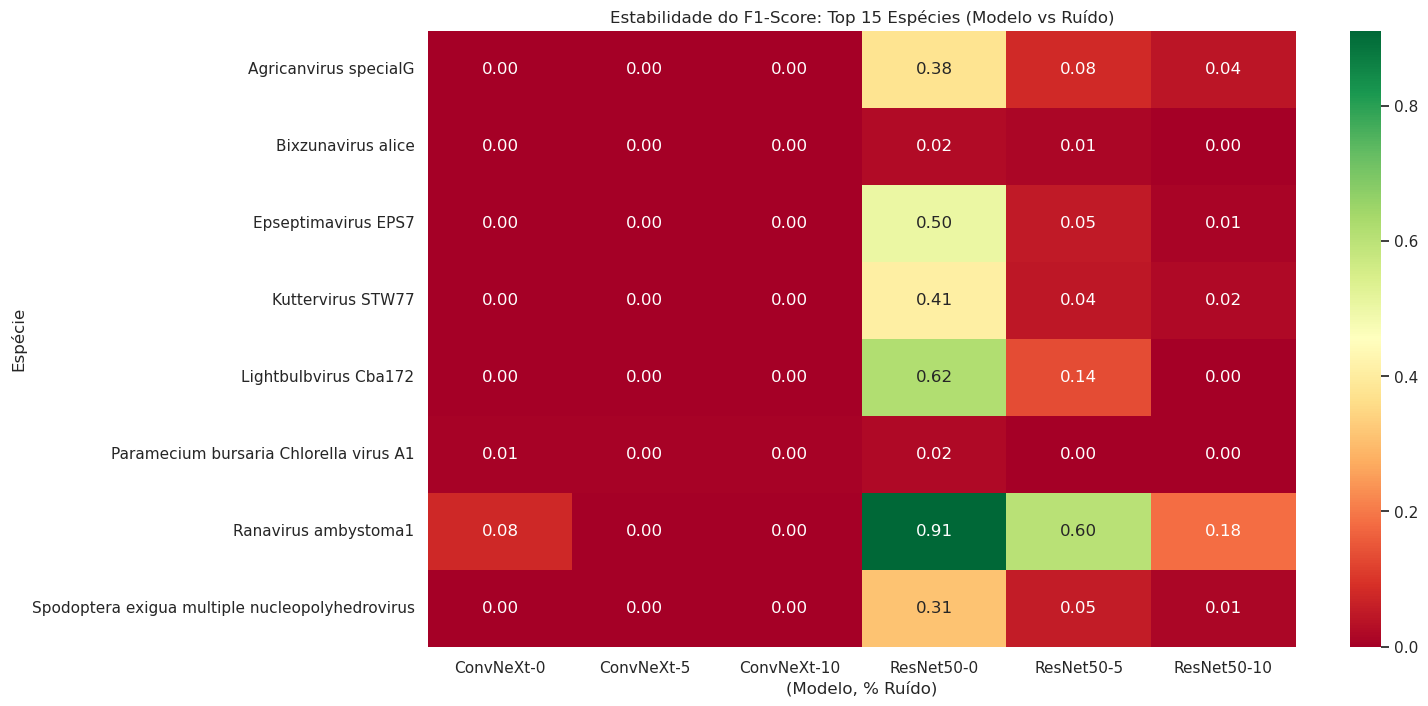

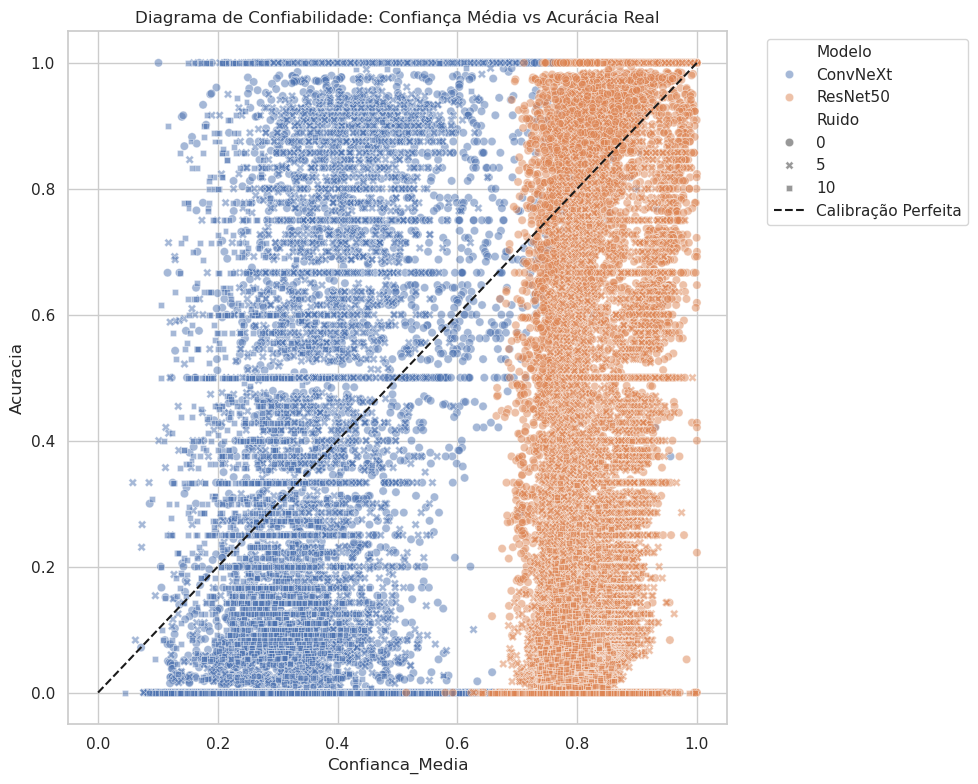

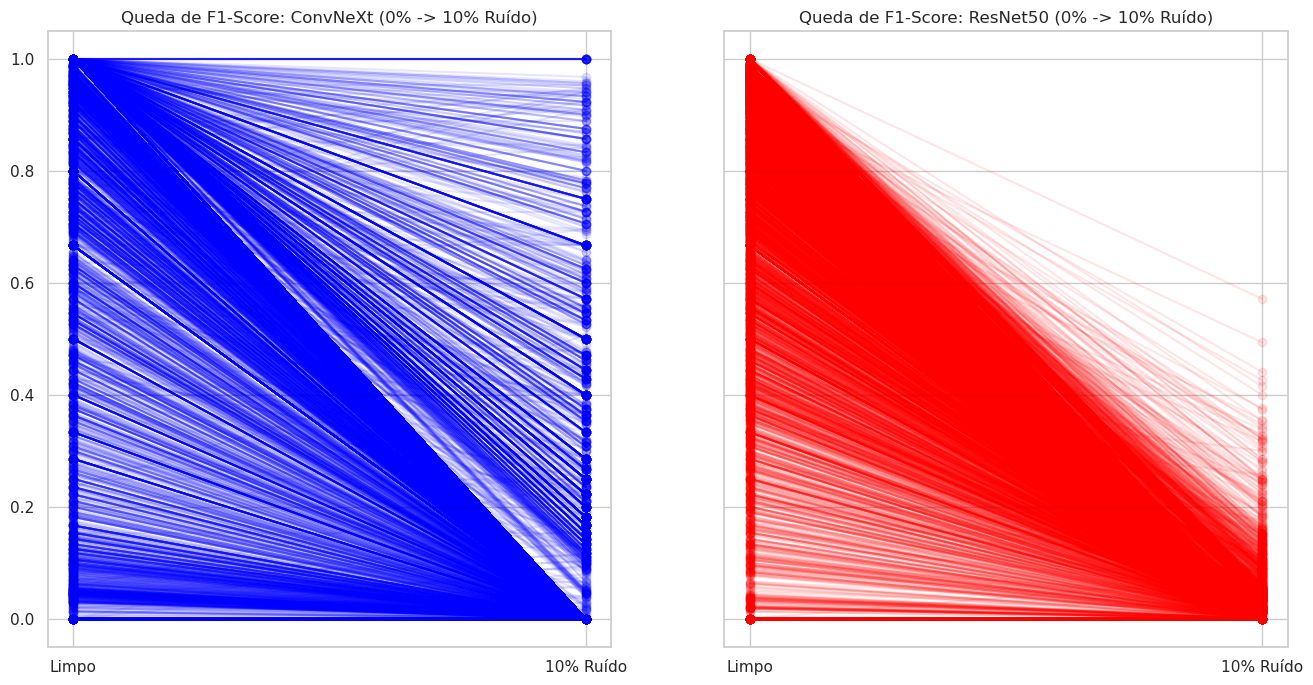

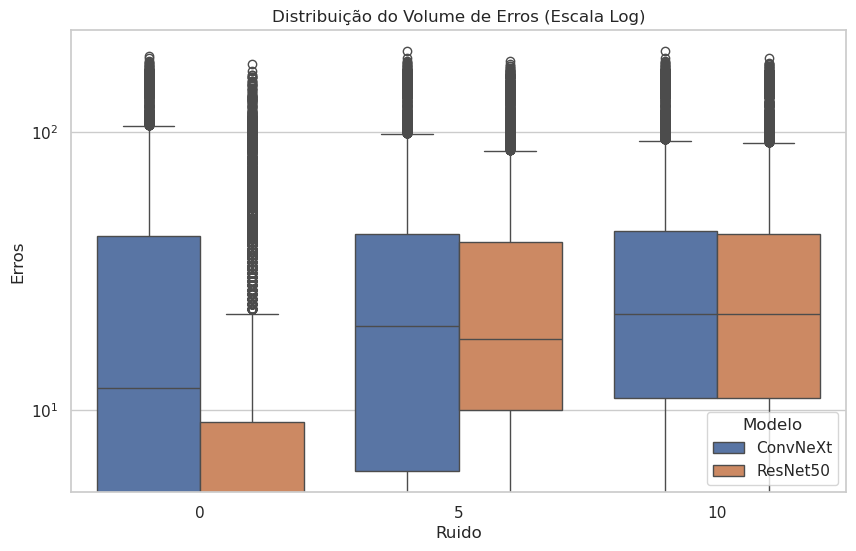

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuração de estilo
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 8]

# 1. Carregamento e Preparação dos Dados
files = {
    'ConvNeXt_0': 'analise_ConvNeXt.csv',
    'ConvNeXt_5': 'analise_ConvNeXt_noise5.csv',
    'ConvNeXt_10': 'analise_ConvNeXt_noise10.csv',
    'ResNet50_0': 'analise_ResNet50.csv',
    'ResNet50_5': 'analise_ResNet50_noise5.csv',
    'ResNet50_10': 'analise_ResNet50_noise10.csv'
}

all_data = []
for label, file in files.items():
    model, noise = label.split('_')
    df = pd.read_csv(file, sep=';', decimal=',')
    df['Modelo'] = model
    df['Ruido'] = int(noise)
    all_data.append(df)

df_total = pd.concat(all_data)

# --- PLOT 1: Heatmap de Performance das Top Espécies ---
# Mostra como as 15 espécies mais comuns sofrem com o ruído em ambos os modelos
top_species = df_total[df_total['Ruido'] == 0].nlargest(15, 'Amostras')['Nome_Especie'].unique()
pivot_df = df_total[df_total['Nome_Especie'].isin(top_species)].pivot_table(
    index='Nome_Especie', columns=['Modelo', 'Ruido'], values='F1_Score'
)

plt.figure(figsize=(14, 8))
sns.heatmap(pivot_df, annot=True, cmap='RdYlGn', fmt=".2f")
plt.title('Estabilidade do F1-Score: Top 15 Espécies (Modelo vs Ruído)')
plt.ylabel('Espécie')
plt.xlabel('(Modelo, % Ruído)')
plt.savefig('heatmap_performance.png')

# --- PLOT 2: Gráfico de Calibração (Confiança vs Acurácia) ---
# Identifica se o modelo está sendo "arrogante" (muita confiança para pouca acurácia)
plt.figure(figsize=(10, 8))
sns.scatterplot(data=df_total, x='Confianca_Media', y='Acuracia', hue='Modelo', style='Ruido', alpha=0.5)
plt.plot([0, 1], [0, 1], '--k', label='Calibração Perfeita')
plt.title('Diagrama de Confiabilidade: Confiança Média vs Acurácia Real')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.savefig('calibracao_confianca.png')

# --- PLOT 3: Slope Chart de Degradação (0% para 10%) ---
# Visualiza quais espécies "despencam" e quais são resilientes
slope_data = df_total[df_total['Ruido'].isin([0, 10])].pivot_table(
    index='Nome_Especie', columns=['Modelo', 'Ruido'], values='F1_Score'
).dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 8), sharey=True)

for brand, ax, color in zip(['ConvNeXt', 'ResNet50'], [ax1, ax2], ['blue', 'red']):
    for i in range(len(slope_data)):
        y_start = slope_data[brand][0].iloc[i]
        y_end = slope_data[brand][10].iloc[i]
        ax.plot([0, 10], [y_start, y_end], marker='o', color=color, alpha=0.1)
    ax.set_title(f'Queda de F1-Score: {brand} (0% -> 10% Ruído)')
    ax.set_xticks([0, 10])
    ax.set_xticklabels(['Limpo', '10% Ruído'])

plt.savefig('slope_degradacao.png')

# --- PLOT 4: Distribuição de Erros por Modelo ---
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_total, x='Ruido', y='Erros', hue='Modelo')
plt.yscale('log') # Escala logarítmica para ver melhor a variação
plt.title('Distribuição do Volume de Erros (Escala Log)')
plt.savefig('boxplot_erros.png')

print("Plots gerados com sucesso.")

Análises visuais geradas.


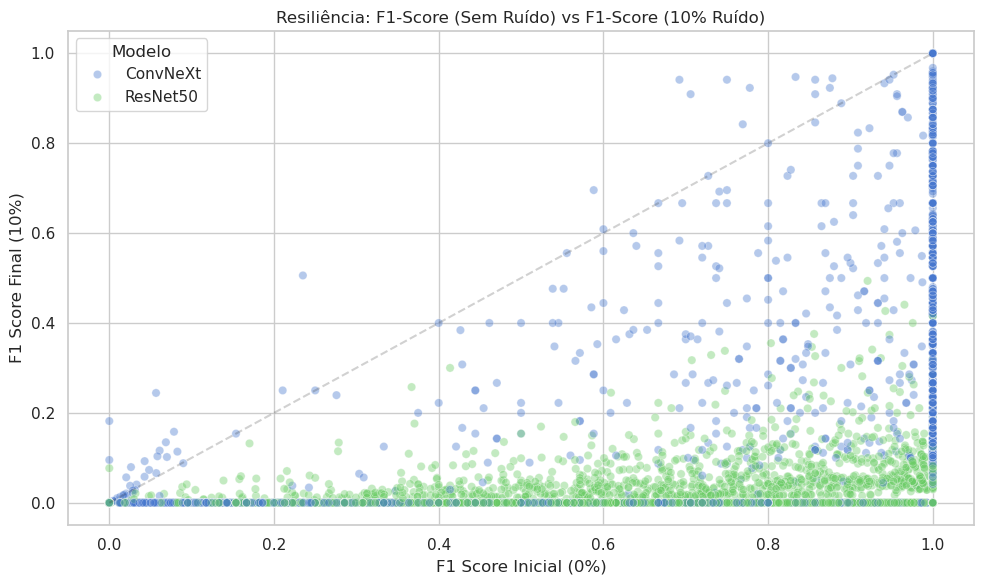

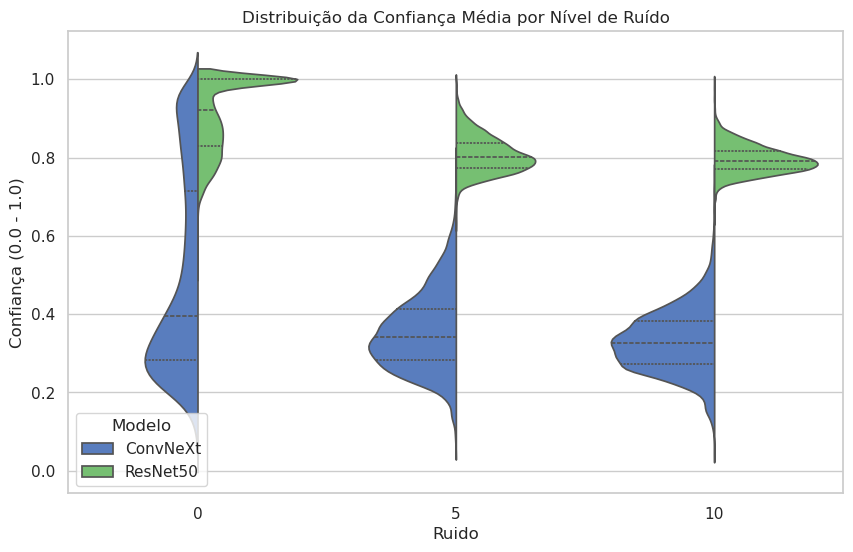

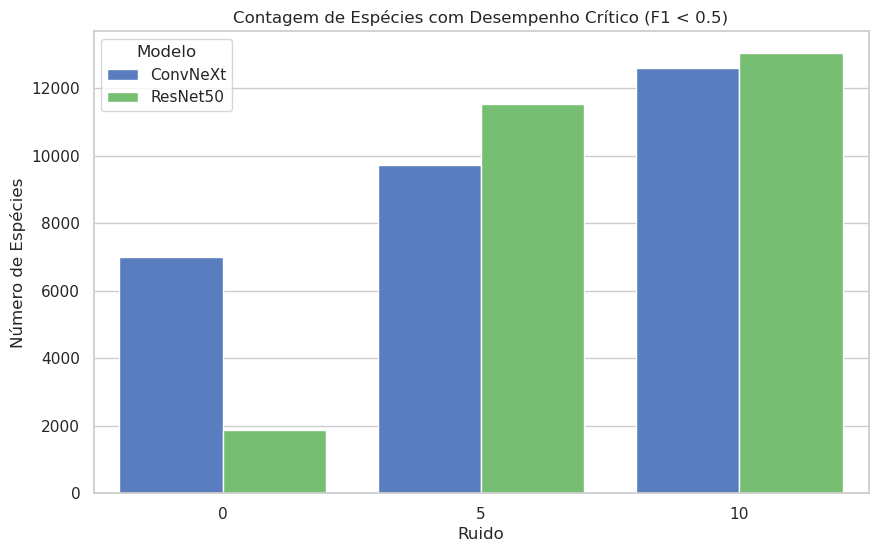

In [67]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configurações globais
plt.style.use('seaborn-v0_8-muted')
colors = {'ConvNeXt': '#2c3e50', 'ResNet50': '#e74c3c'}

# --- FUNÇÃO PARA CARREGAR E UNIFICAR ---
def load_and_merge():
    dfs = []
    files = {
        'ConvNeXt': ['analise_ConvNeXt.csv', 'analise_ConvNeXt_noise5.csv', 'analise_ConvNeXt_noise10.csv'],
        'ResNet50': ['analise_ResNet50.csv', 'analise_ResNet50_noise5.csv', 'analise_ResNet50_noise10.csv']
    }
    noises = [0, 5, 10]
    
    for model, filenames in files.items():
        for f, n in zip(filenames, noises):
            temp = pd.read_csv(f, sep=';', decimal=',')
            temp['Modelo'] = model
            temp['Ruido'] = n
            dfs.append(temp)
    return pd.concat(dfs)

df_all = load_and_merge()

# --- PLOT 1: Scatter de Robustez (F1 0% vs F1 10%) ---
# Ajuda a visualizar quem "sobrevive" ao ruído extremo
plt.figure(figsize=(10, 6))
pivot_robust = df_all.pivot_table(index=['Nome_Especie', 'Modelo'], columns='Ruido', values='F1_Score').reset_index()
sns.scatterplot(data=pivot_robust, x=0, y=10, hue='Modelo', alpha=0.4)
plt.plot([0, 1], [0, 1], 'k--', alpha=0.2)
plt.title('Resiliência: F1-Score (Sem Ruído) vs F1-Score (10% Ruído)')
plt.xlabel('F1 Score Inicial (0%)')
plt.ylabel('F1 Score Final (10%)')
plt.tight_layout()
plt.savefig('robustness_scatter.png')

# --- PLOT 2: Violin Plot de Confiança vs Ruído ---
# Revela a distribuição da "certeza" dos modelos
plt.figure(figsize=(10, 6))
sns.violinplot(data=df_all, x='Ruido', y='Confianca_Media', hue='Modelo', split=True, inner="quart")
plt.title('Distribuição da Confiança Média por Nível de Ruído')
plt.ylabel('Confiança (0.0 - 1.0)')
plt.savefig('confidence_violin.png')

# --- PLOT 3: Análise de "Vulnerabilidade Crítica" ---
# Quantas espécies caem abaixo de um limiar aceitável (ex: F1 < 0.5)
vulnerability = df_all[df_all['F1_Score'] < 0.5].groupby(['Modelo', 'Ruido']).size().reset_index(name='Qtd_Especies_Falhas')
plt.figure(figsize=(10, 6))
sns.barplot(data=vulnerability, x='Ruido', y='Qtd_Especies_Falhas', hue='Modelo')
plt.title('Contagem de Espécies com Desempenho Crítico (F1 < 0.5)')
plt.ylabel('Número de Espécies')
plt.savefig('failure_count.png')

print("Análises visuais geradas.")

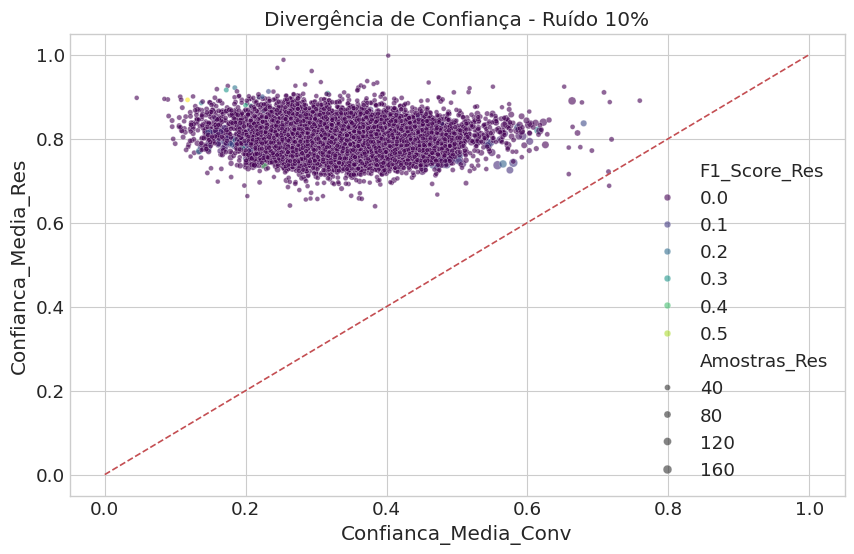

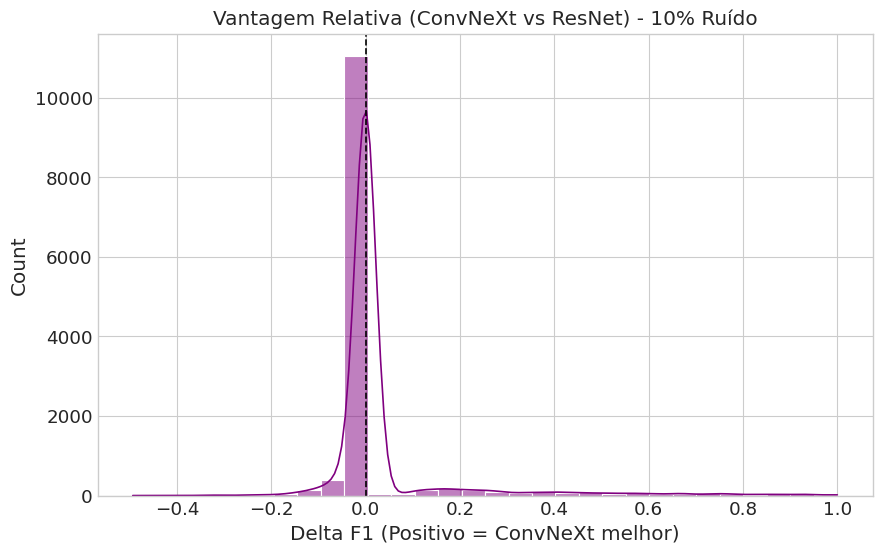

In [68]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configuração de estilo para publicação
sns.set_context("paper", font_scale=1.5)
plt.style.use('seaborn-v0_8-whitegrid')

def gerar_analise_voter(file_conv, file_res, noise_level):
    df_c = pd.read_csv(file_conv, sep=';', decimal=',')
    df_r = pd.read_csv(file_res, sep=';', decimal=',')
    
    # Merge para comparação direta por espécie
    df_comp = pd.merge(df_c, df_r, on='Nome_Especie', suffixes=('_Conv', '_Res'))
    
    # 1. Plot de Concordância vs Performance
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=df_comp, x='Confianca_Media_Conv', y='Confianca_Media_Res', 
                    hue='F1_Score_Res', size='Amostras_Res', alpha=0.6, palette='viridis')
    plt.plot([0, 1], [0, 1], '--r', label='Linha de Concordância')
    plt.title(f'Divergência de Confiança - Ruído {noise_level}%')
    plt.savefig(f'divergencia_confianca_{noise_level}.png')

    # 2. Plot de "Ganhos Potenciais"
    # Identifica espécies onde um modelo acerta e o outro erra feio
    df_comp['Delta_F1'] = df_comp['F1_Score_Conv'] - df_comp['F1_Score_Res']
    
    plt.figure(figsize=(10, 6))
    sns.histplot(df_comp['Delta_F1'], bins=30, kde=True, color='purple')
    plt.axvline(0, color='black', linestyle='--')
    plt.title(f'Vantagem Relativa (ConvNeXt vs ResNet) - {noise_level}% Ruído')
    plt.xlabel('Delta F1 (Positivo = ConvNeXt melhor)')
    plt.savefig(f'delta_f1_{noise_level}.png')

# Exemplo de execução para o cenário de 10% de ruído
gerar_analise_voter('analise_ConvNeXt_noise10.csv', 'analise_ResNet50_noise10.csv', 10)

<Figure size 1000x700 with 0 Axes>

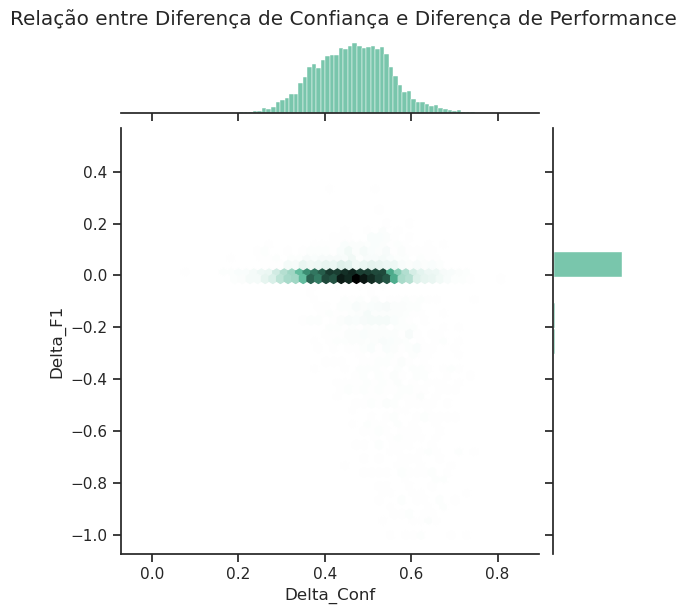

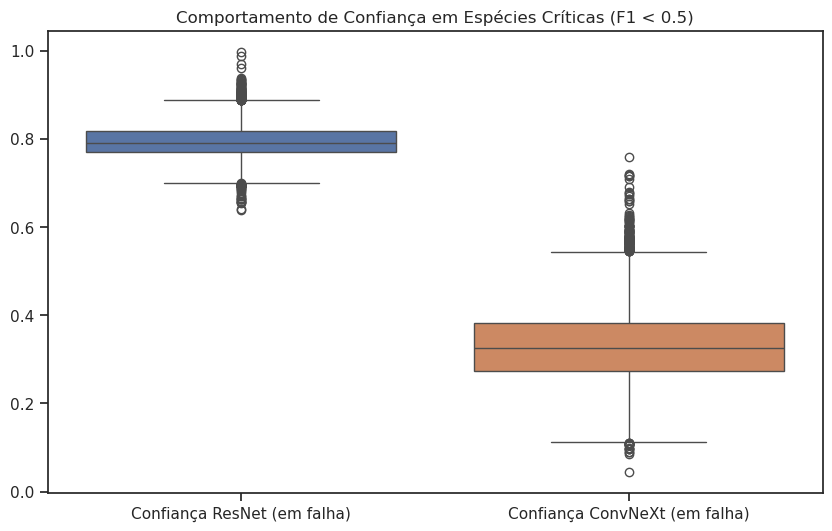

In [73]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração de estilo
sns.set_theme(style="ticks")

def analise_especializada_voter(df_conv, df_res):
    # Unificando os dados para comparação direta
    df_merged = pd.merge(df_conv, df_res, on='Nome_Especie', suffixes=('_C', '_R'))
    
    # 1. Plot de Delta de Confiança vs Delta de F1
    # Ajuda a identificar se o modelo mais confiante é realmente o que mais acerta
    df_merged['Delta_Conf'] = df_merged['Confianca_Media_R'] - df_merged['Confianca_Media_C']
    df_merged['Delta_F1'] = df_merged['F1_Score_R'] - df_merged['F1_Score_C']
    
    plt.figure(figsize=(10, 7))
    sns.jointplot(data=df_merged, x='Delta_Conf', y='Delta_F1', kind="hex", color="#4CB391")
    plt.suptitle('Relação entre Diferença de Confiança e Diferença de Performance', y=1.02)
    plt.savefig('joint_delta_analysis.png')

    # 2. Boxplot de "Faixas de Risco"
    # Compara a confiança do ResNet50 nas espécies onde ele tem F1 baixo
    plt.figure(figsize=(10, 6))
    df_low_f1 = df_merged[df_merged['F1_Score_R'] < 0.5]
    sns.boxplot(data=df_low_f1[['Confianca_Media_R', 'Confianca_Media_C']])
    plt.xticks([0, 1], ['Confiança ResNet (em falha)', 'Confiança ConvNeXt (em falha)'])
    plt.title('Comportamento de Confiança em Espécies Críticas (F1 < 0.5)')
    plt.savefig('failure_confidence_comparison.png')

# Executar com seus dados carregados
df_conv_10 = pd.read_csv("analise_ConvNeXt_noise10.csv", sep=';', decimal=',')
df_res_10 = pd.read_csv("analise_ResNet50_noise10.csv", sep=';', decimal=',')
analise_especializada_voter(df_conv_10, df_res_10)